[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AndresOrdonez369/deepLearningWeek1/blob/main/semana3/proyectos/NB06_reutilizar_y_explicar.ipynb)

# NB06 · Reutilizar y explicar: ¿puedo aprovechar lo que otra red aprendió y explicar lo que decide?
**Neural Networks: Deep Learning · UIDE · Semana 3 · Tema 2** — Docente: Andrés Ordóñez-Bolaños

**La necesidad:** en el Tema 1 vimos que una red necesita **muchos datos** para generalizar, y que exacto no es lo mismo que confiable. Este Colab responde dos preguntas de la vida real:
1. **Tengo muy pocos datos. ¿Puedo reutilizar lo que otra red ya aprendió?** Es el **transfer learning**, la forma en que hoy se entrenan casi todos los modelos.
2. **¿Por qué decidió eso la red, y puedo creerle a la explicación?** Primero con fotos (¿dónde miró?) y después con un caso que nos toca de cerca: una **cooperativa ficticia** que le niega un crédito a una socia. En Ecuador, desde marzo de 2026, una norma permite a las personas afectadas por decisiones automatizadas pedir una explicación de la lógica del algoritmo (lectura de tendencia).

### Cómo usar este Colab (2 minutos)
**Todo el código ya está escrito: tú lees, predices, ejecutas y comparas.** No tienes que programar nada para avanzar.

1. **Archivo → Guardar una copia en Drive.** Así tus cambios quedan guardados.
2. Ejecuta la celda **Configuración** y después avanza en orden con `Shift + Enter`.
3. Cada parte sigue el mismo orden:
   **Qué vas a hacer → la necesidad → ejemplo → el nombre → la fórmula («Léelo así») → Qué hace este código → 🔮 Antes de ejecutar: ¿qué crees que saldrá? → ejecuta → Qué deberías ver → 💭 Para pensar.**
4. En **🔮 Antes de ejecutar** detente cinco segundos y apuesta un resultado. Acertar no importa; **comparar** sí.
5. En **💭 Para pensar** responde con tu pareja y después abre **Ver respuesta**.
6. Las celdas **🧪 Experimenta** son opcionales: cambia **un solo** valor marcado y vuelve a ejecutar.
7. Al final hay **✍️ Ejercicios** (se responden leyendo tus resultados) y **10 preguntas** para comprobar que entendiste. **No tiene nota.** Trabajen en parejas y equivóquense sin miedo.

> **🛟 Si algo falla**
> - `NameError: name 'x' is not defined` → te saltaste una celda de arriba. Usa **Entorno de ejecución → Ejecutar anteriores** (o **Ejecutar todo**).
> - La descarga de las fotos falla (`URL fetch failure`) → espera unos segundos y vuelve a ejecutar la celda de la Parte 0.
> - `ModuleNotFoundError: No module named 'shap'` → la celda de la Parte 4 lo instala sola; si falla, ejecuta `%pip install shap` en una celda nueva y vuelve a intentar.
> - Va lento → normal en CPU: el Colab completo tarda unos 2 minutos en la CPU de Colab (lo más largo son las Partes 1 y 2, menos de un minuto cada una). Si quieres, **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**.
> - Tus porcentajes difieren un poco de los de «Qué deberías ver» → normal: otra computadora redondea distinto. Lo que importa es el **patrón**.
> - Si cambiaste algo y ya no sabes qué: **Entorno de ejecución → Reiniciar y ejecutar todo**.

### Mapa del Colab
| Parte | Qué aprendes | Lámina |
|---|---|---|
| 0 | Configuración y datos: la CNN de siempre, en piezas | 24 |
| 1 | Transfer learning: la red que nunca vio prendas de arriba (5, 20 y 100 fotos) | 25–28 |
| 2 | ¿Dónde miró la red? Oclusión, Grad-CAM y gradiente × imagen, a mano | 29–30 |
| 3 | La prueba de cordura: ¿la explicación explica a la red? | 31 |
| 4 | Explicar una decisión de crédito: importancia por permutación y SHAP | 32 |
| 5 | Lo que le sirve a la socia: el contrafactual | 33 |
| 6 | ¿Trata a todos por igual? Por zona, con y sin la columna rural | 34 |
| 🏁 | Resumen · la lectura · **✍️ Ejercicios** · **Para comprobar que entendiste** · **Experimento 6: ¿dónde pones la raya?** | 36–37 |

En clase (lámina 37, unos 40 minutos): prioridad **1, 2, 3 y 4**. Las partes 5 y 6 son cortas (no entrenan casi nada); si no alcanza el tiempo, quedan para casa.

In [1]:
# @title Configuración · ejecuta esta celda primero (no necesitas abrirla)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow info messages
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from scipy.stats import spearmanr              # rank correlation (Part 3)
from sklearn.metrics import roc_auc_score      # AUC (Part 4)

SEED = 2026
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=140)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

# The same colors as the slides: amber = transfer / attention, azure = towards approving, mint = passes, coral = towards rejecting / fails
AMBAR, AZUL, MENTA, CORAL, TINTA, LILA = "#E39A12", "#2B8FD6", "#12A37F", "#E0533D", "#1F2A3A", "#8B6FD1"

# The 10 classes of Fashion-MNIST, in Spanish, in the order of the labels 0..9
CLASES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "zapatilla", "bolso", "botín"]

def ver(img, ax, title="", cmap="gray"):
    # Draws a 28 x 28 image (values 0..1) without axes
    ax.imshow(np.squeeze(img), cmap=cmap, vmin=0, vmax=1); ax.set_title(title, fontsize=10); ax.axis("off")

def encima(img, mapa, ax, title=""):
    # Draws the photo in gray and a heat map (0..1) on top: bright = "the network looked here"
    ax.imshow(np.squeeze(img), cmap="gray", vmin=0, vmax=1)
    ax.imshow(mapa, cmap="inferno", alpha=0.6, vmin=0, vmax=1)
    ax.set_title(title, fontsize=10); ax.axis("off")

print("Listo. TensorFlow", tf.__version__, "| Keras", keras.__version__)

Listo. TensorFlow 2.21.0 | Keras 3.15.1


---
## 0 · Configuración y datos: la CNN de siempre, en piezas
📽 Lámina 24

**Qué vas a hacer:** cargar Fashion-MNIST y escribir la parte convolucional de la CNN de siempre como una **lista de capas**, para poder pasarla de una red a otra.

**La necesidad:** para reutilizar lo que una red aprendió, necesitamos separar la red en dos partes:
- **la base** (las capas convolucionales): aprende a **ver** bordes, curvas, texturas, formas;
- **la cabeza** (la última capa `Dense`): decide **qué prenda** es.

**Qué hace este código:** carga y prepara las fotos (como en el NB05) y define `base_conv()`, que devuelve las 5 capas de la base: `Conv2D(16)` → `MaxPooling2D` → `Conv2D(32)` → `MaxPooling2D` → `Flatten`.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()   # downloads once
x_train = (x_train / 255.0).astype("float32")[..., None]   # 0..255 -> 0..1, and add the channel axis
x_test = (x_test / 255.0).astype("float32")[..., None]
print("x_train:", x_train.shape, "| x_test:", x_test.shape)


def base_conv():
    # The convolutional "base" of the CNN from week 2 (it learns to SEE); the head (Dense) is added separately
    return [layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(2),
            layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(2), layers.Flatten()]

x_train: (60000, 28, 28, 1) | x_test: (10000, 28, 28, 1)


**Qué deberías ver:** `x_train: (60000, 28, 28, 1) | x_test: (10000, 28, 28, 1)`.

---
## 1 · Transfer learning: la red que nunca vio prendas de arriba
📽 Láminas 25–28

**Qué vas a hacer:** enseñarle a una red a distinguir **4 prendas de arriba muy parecidas** (camiseta, suéter, abrigo y camisa) con **muy pocas fotos**: 5, 20 o 100 por clase. Lo haremos de tres formas y compararemos.

**La necesidad:** en tu proyecto casi nunca tendrás 60 000 fotos etiquetadas. Pero sí existen redes que ya aprendieron a **ver** con millones de fotos. ¿Podemos aprovechar esa experiencia?

**Ejemplo:** contratar a un **profesional con experiencia** y darle una **inducción corta** sobre tu empresa. Aprende rápido, porque ya sabe trabajar. Pero trae **hábitos** de trabajos anteriores que no conoces del todo (lectura de tendencia).

**El nombre:** **transfer learning** (transferencia de aprendizaje). La «red con experiencia» aquí es una CNN entrenada con **6 clases que no son prendas de arriba** (pantalón, vestido, sandalia, zapatilla, bolso y botín): nunca vio una camiseta. Tres estrategias:

| Estrategia | Qué se entrena | Analogía |
|---|---|---|
| **Desde cero** | todo, empezando al azar | contratar a alguien sin experiencia |
| **Congelar** (`trainable = False`) | solo la cabeza nueva; la base se copia y no se toca | usar su experiencia tal cual y enseñarle solo la última parte |
| **Ajuste fino** (*fine-tuning*) | después de congelar, **todo**, con pasos muy pequeños (lr = 0.0001) | dejar que también ajuste un poco sus hábitos, con cuidado |

**La cuenta de parámetros:** la red completa tiene **8 004** parámetros: la base, 160 + 4 640 = 4 800, y la cabeza, 800 × 4 + 4 = **3 204** (800 = 5 × 5 × 32 números que salen del `Flatten`; 4 clases). Al congelar, se entrenan **solo 3 204**.

**Qué hace este código (primera celda):**
- Entrena la red base 5 épocas con las fotos de las 6 clases (unos 36 000) y mide su exactitud en esas clases.
- Copia los pesos aprendidos de su base (`W`): esa es la «experiencia».
- Dibuja una foto de cada clase: lo que **sabe** la red base y lo **nuevo** que tendrá que aprender.

🔮 **Antes de ejecutar:** distinguir pantalón de bolso es fácil. ¿Qué exactitud esperas en esas 6 clases?

red base: 36,000 fotos de 6 clases · 11 s · exactitud en esas clases: 96.8%


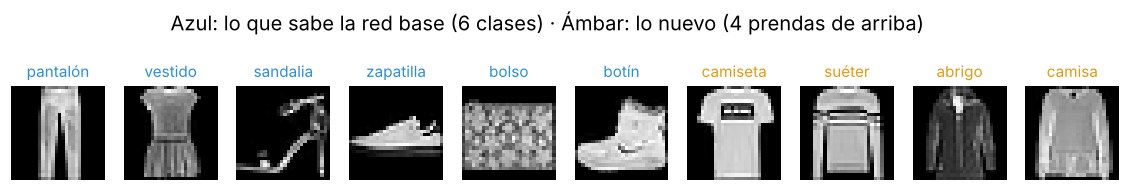

In [3]:
BASE, TOPS = [1, 3, 5, 7, 8, 9], [0, 2, 4, 6]      # what the base network learns / the new task (4 kinds of tops)
mk = np.isin(y_train, BASE)                          # training photos of the 6 base classes
remap = {c: i for i, c in enumerate(BASE)}           # labels 1,3,5,7,8,9 -> 0..5

t0 = time.time()
keras.utils.set_random_seed(SEED)
convs = base_conv()                                  # keep a handle on these layers to copy their weights later
base = keras.Sequential([keras.Input((28, 28, 1)), *convs, layers.Dense(len(BASE), activation="softmax")])
base.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
base.fit(x_train[mk], np.array([remap[c] for c in y_train[mk]]), epochs=5, batch_size=128, verbose=0)
mt = np.isin(y_test, BASE)
print(f"red base: {mk.sum():,} fotos de 6 clases · {time.time() - t0:.0f} s · exactitud en esas clases: "
      f"{base.evaluate(x_test[mt], np.array([remap[c] for c in y_test[mt]]), verbose=0)[1]:.1%}")

W = [l.get_weights() for l in convs]                 # the "experience": the learned weights of the base
tm = {c: i for i, c in enumerate(TOPS)}              # labels 0,2,4,6 -> 0..3

fig, axs = plt.subplots(1, 10, figsize=(13, 1.9))
for ax, c in zip(axs, BASE + TOPS):
    ver(x_train[np.where(y_train == c)[0][0]], ax, CLASES[c])
    ax.title.set_color(AZUL if c in BASE else AMBAR)
plt.suptitle("Azul: lo que sabe la red base (6 clases) · Ámbar: lo nuevo (4 prendas de arriba)", y=1.08); plt.show()

**Qué deberías ver:** unas 36 000 fotos y alrededor de **96.8 %** en las 6 clases de la base. En las fotos, las 4 prendas de arriba se parecen muchísimo entre sí: es una tarea **difícil** (el azar es 25 %).

**Qué hace este código (segunda celda):**
- `pick(X, Y, n)` toma las primeras `n` fotos de cada una de las 4 prendas de arriba. El examen son 1 000 por clase (4 000 fotos) y el simulacro, 50 por clase (200), siempre las mismas.
- Para cada tamaño (5, 20 y 100 fotos por clase) entrena las tres estrategias, con *early stopping* (la «parada a tiempo» del NB05):
  1. **desde cero**: una red nueva con la misma forma;
  2. **congelada**: una red nueva a la que le **copiamos** los pesos de la base (`set_weights(w)`) y le ponemos `trainable = False`; solo aprende la cabeza;
  3. **ajuste fino**: a la congelada le quitamos el candado (`trainable = True`) y la entrenamos un poco más con un learning rate **100 veces más pequeño** (0.0001), para no borrar la experiencia.
- Tarda alrededor de un minuto.

🔮 **Antes de ejecutar:** ¿con cuántas fotos crees que la experiencia ayuda más: con 5 o con 100 por clase?

  5 fotos por clase · desde cero 30.6% · congelada 45.9% (entrena 3,204 de 8,004) · ajuste fino 47.2% · 6 s


 20 fotos por clase · desde cero 61.2% · congelada 62.7% (entrena 3,204 de 8,004) · ajuste fino 62.7% · 17 s


100 fotos por clase · desde cero 68.8% · congelada 66.7% (entrena 3,204 de 8,004) · ajuste fino 68.0% · 29 s


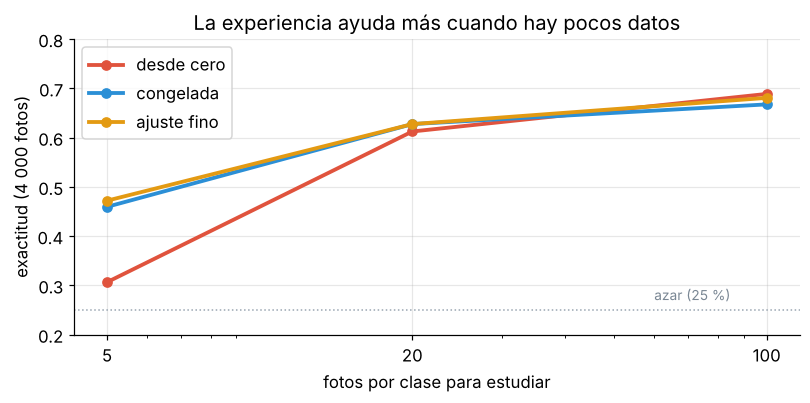

In [4]:
def pick(X, Y, n, start=0):
    # The photos number start..start+n-1 of each of the 4 tops, with labels 0..3
    idx = np.concatenate([np.where(Y == c)[0][start:start + n] for c in TOPS])
    return X[idx], np.array([tm[c] for c in Y[idx]])


xte4, yte4 = pick(x_test, y_test, 1000)                   # final exam: 4 000 photos
xv4, yv4 = pick(x_train, y_train, 50, start=1000)         # simulacro: 200 photos, never used to study


def parar():
    # A new early-stopping "brake" for every training run
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)


tabla = {}
t0 = time.time()
for n in (5, 20, 100):
    xt4, yt4 = pick(x_train, y_train, n)                  # only n photos per class to study
    # 1) from scratch: random starting weights
    keras.utils.set_random_seed(SEED)
    s0 = keras.Sequential([keras.Input((28, 28, 1)), *base_conv(), layers.Dense(4, activation="softmax")])
    s0.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    s0.fit(xt4, yt4, epochs=100, batch_size=16, validation_data=(xv4, yv4), callbacks=[parar()], verbose=0)
    # 2) frozen: copy the experience into a new base and lock it
    c2 = base_conv()
    keras.utils.set_random_seed(SEED)
    fz = keras.Sequential([keras.Input((28, 28, 1)), *c2, layers.Dense(4, activation="softmax")])   # new head: 4 classes
    for l, w in zip(c2, W):
        l.set_weights(w)                                  # transplant the learned weights...
        l.trainable = False                               # ...and freeze them: only the head learns
    fz.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    fz.fit(xt4, yt4, epochs=100, batch_size=16, validation_data=(xv4, yv4), callbacks=[parar()], verbose=0)
    congelada = fz.evaluate(xte4, yte4, verbose=0)[1]
    entrenables = int(sum(np.prod(w.shape) for w in fz.trainable_weights))
    # 3) fine-tuning: unlock everything and keep training with tiny steps
    for l in c2:
        l.trainable = True
    fz.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])  # recompile after unlocking
    fz.fit(xt4, yt4, epochs=40, batch_size=16, validation_data=(xv4, yv4), callbacks=[parar()], verbose=0)
    tabla[n] = [s0.evaluate(xte4, yte4, verbose=0)[1], congelada, fz.evaluate(xte4, yte4, verbose=0)[1]]
    print(f"{n:3d} fotos por clase · desde cero {tabla[n][0]:.1%} · congelada {tabla[n][1]:.1%} "
          f"(entrena {entrenables:,} de {s0.count_params():,}) · ajuste fino {tabla[n][2]:.1%} · {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ns = [5, 20, 100]
for k, (nombre, color) in enumerate([("desde cero", CORAL), ("congelada", AZUL), ("ajuste fino", AMBAR)]):
    ax.plot(ns, [tabla[n][k] for n in ns], "o-", color=color, lw=2.5, label=nombre)
ax.axhline(0.25, color="#9AA6B2", ls=":", lw=1); ax.text(60, 0.27, "azar (25 %)", color="#7A8794", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(ns); ax.set_xticklabels(["5", "20", "100"]); ax.set_ylim(0.2, 0.8)
ax.set_xlabel("fotos por clase para estudiar"); ax.set_ylabel("exactitud (4 000 fotos)")
ax.set_title("La experiencia ayuda más cuando hay pocos datos"); ax.legend(); plt.tight_layout(); plt.show()

**Qué deberías ver:**

| Fotos por clase | Desde cero (8 004 parámetros) | Congelada (entrena 3 204) | Ajuste fino |
|---|---|---|---|
| **5** (20 fotos) | ≈ **30.6 %** | ≈ **45.9 %** | ≈ **47.2 %** |
| 20 (80 fotos) | ≈ 61.2 % | ≈ 62.7 % | ≈ 62.7 % |
| 100 (400 fotos) | ≈ **68.8 %** | ≈ 66.7 % | ≈ 68.0 % |

**Léelo así, con honestidad:** con **5 fotos por clase**, la experiencia heredada gana unos **15 puntos** (desde cero casi adivina). Con 100, entrenar desde cero **empata o gana**: ya hay datos suficientes. Transfer learning ayuda **sobre todo cuando hay pocos datos**.

**En la vida real** (lámina 28) la base aprendió de **millones** de fotos (ImageNet) y la ventaja es mucho mayor. En Keras son dos líneas:

```python
base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(160, 160, 3))
base.trainable = False      # freeze the experience; then add your own head and train only that
```

Con los modelos de lenguaje se hace lo mismo con técnicas como **LoRA**, que ajustan solo una pequeña parte del modelo.

### 💭 Para pensar

**1.** ¿Por qué la red congelada aprende con tan pocas fotos?

<details><summary>Ver respuesta</summary>

Porque solo tiene que aprender **3 204** parámetros (la cabeza), no 8 004, y lo que recibe la cabeza ya son rasgos útiles (bordes, mangas, cuellos) que la base aprendió con 36 000 fotos de otras prendas. Con 20 fotos, aprender a **ver** desde cero es casi imposible.
</details>

**2.** ¿Por qué el ajuste fino usa un learning rate 100 veces más pequeño?

<details><summary>Ver respuesta</summary>

Para no **borrar** la experiencia: con pasos grandes, los primeros lotes (con muy pocas fotos) cambiarían mucho los pesos de la base y se perdería lo aprendido. Con pasos pequeños, la base solo se **acomoda** un poco a la tarea nueva.
</details>

**3.** La base aprendió con pantalones, zapatos y bolsos. ¿Qué «hábito» podría traer que no te sirva?

<details><summary>Ver respuesta</summary>

Por ejemplo, fijarse en la **silueta** general (lo que distingue un zapato de un pantalón), cuando para separar camisa de camiseta importan detalles finos (botones, cuello). En la vida real, una base entrenada con fotos de otro país u otra época puede traer **sesgos** que no conocemos: heredamos lo que no podemos auditar.
</details>

---
## 2 · ¿Dónde miró la red?
📽 Láminas 29–30

**Qué vas a hacer:** entrenar la CNN de 10 clases (la del NB03) y fabricar, **a mano**, tres «mapas de calor» que intentan responder: **¿en qué parte de la foto se fijó para decidir?**

**La necesidad:** una red puede acertar **por la razón equivocada**. Si un modelo dice «neumonía», el mapa debería iluminar el pulmón, no una etiqueta del hospital en la esquina de la radiografía (lectura). Mirar dónde mira es la primera revisión.

**El nombre:** son **explicaciones *post hoc***: observan la red ya entrenada y tratan de describir qué influyó. Tres métodos:

**1. Oclusión** (tapar con la mano). Tapamos un cuadro de 6 × 6 píxeles (lo ponemos en negro), lo vamos corriendo por toda la foto y medimos cuánto baja la probabilidad de la clase correcta:

$$\text{importancia(zona)} = p_{\text{clase}}(\text{foto}) - p_{\text{clase}}(\text{foto con la zona tapada})$$

**Léelo así:** "si al tapar esta zona la red duda mucho, esa zona le importaba".

**2. Grad-CAM** (Selvaraju et al., 2017). Usa la **última capa convolucional**: 32 mapas de 11 × 11 ($A^k$). Para cada mapa calcula, con el gradiente, cuánto empuja la probabilidad de la clase ($w_k$), y suma los mapas pesados:

$$w_k = \text{promedio}_{i,j}\ \frac{\partial\, p_{\text{clase}}}{\partial A^k_{ij}} \qquad\qquad \text{Grad-CAM} = \text{ReLU}\Big(\sum_k w_k\, A^k\Big)$$

**Léelo así:** "los mapas que más ayudan a decir *botín* pesan más; nos quedamos con lo positivo (ReLU) y lo agrandamos a 28 × 28".

**3. Gradiente × imagen.** Para cada píxel: cuánto cambia la probabilidad si ese píxel cambia un poco, multiplicado por su brillo:

$$\text{mapa}_{ij} = \Big|\ \frac{\partial\, p_{\text{clase}}}{\partial x_{ij}} \cdot x_{ij}\ \Big|$$

**Qué hace este código (primera celda):** entrena la CNN de 10 clases con las 60 000 fotos (5 épocas, como en el NB03; tarda alrededor de un minuto) y define las tres funciones, comentadas línea por línea.

In [5]:
t0 = time.time()
keras.utils.set_random_seed(SEED)
cnn10 = keras.Sequential([keras.Input((28, 28, 1)), *base_conv(), layers.Dense(10, activation="softmax")])   # the NB03 CNN
cnn10.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn10.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=0)
print(f"CNN de 10 clases · {time.time() - t0:.0f} s · examen final: {cnn10.evaluate(x_test, y_test, verbose=0)[1]:.1%}")


def oclusion(model, x, cls, k=6, s=2):
    # Cover a k x k patch (set it to black), slide it with step s, and measure how much p(cls) drops
    p0 = model.predict(x[None], verbose=0)[0, cls]          # probability with nothing covered
    H = np.zeros((28, 28)); C = np.zeros((28, 28)); batch, pos = [], []
    for i in range(0, 28 - k + 1, s):
        for j in range(0, 28 - k + 1, s):
            xx = x.copy(); xx[i:i + k, j:j + k, 0] = 0      # the photo with one patch covered
            batch.append(xx); pos.append((i, j))
    P = model.predict(np.array(batch), verbose=0)[:, cls]   # all covered versions at once (144 photos)
    for (i, j), p in zip(pos, P):
        H[i:i + k, j:j + k] += p0 - p                       # how much it dropped, credited to every covered pixel
        C[i:i + k, j:j + k] += 1                            # how many patches covered each pixel
    return H / np.maximum(C, 1)                             # average drop per pixel


def gradcam(model, x, cls):
    # Grad-CAM on the last convolutional layer (layer number 2: Conv2D(32), output 11 x 11 x 32)
    inp = keras.Input((28, 28, 1)); h = inp; conv_out = None
    for i, l in enumerate(model.layers):                    # rebuild the network to also get the conv output
        h = l(h)
        if i == 2:
            conv_out = h
    g_model = keras.Model(inp, [conv_out, h])
    with tf.GradientTape() as g:
        co, p = g_model(x[None])                            # co: the 32 maps A^k; p: the 10 probabilities
        s = p[0, cls]                                       # the probability of the class we explain
    gr = g.gradient(s, co)[0]                               # d p / d A^k, for every map and position
    w = tf.reduce_mean(gr, axis=(0, 1))                     # w_k: average over the 11 x 11 positions
    cam = tf.nn.relu(tf.reduce_sum(co[0] * w, -1)).numpy()  # weighted sum of the maps, keep the positive part
    cam = tf.image.resize(cam[..., None], (28, 28)).numpy()[..., 0]   # 11 x 11 -> 28 x 28
    return cam / (cam.max() + 1e-8)                         # scale to 0..1


def grad_x(model, x, cls):
    # |gradient x image|: how sensitive p(cls) is to every pixel, times the pixel's brightness
    xt = tf.convert_to_tensor(x[None])
    with tf.GradientTape() as g:
        g.watch(xt)                                         # gradients with respect to the pixels
        s = model(xt)[0, cls]
    gr = g.gradient(s, xt).numpy()[0, :, :, 0]
    return np.abs(gr * x[:, :, 0])

CNN de 10 clases · 20 s · examen final: 87.7%


**Qué deberías ver:** alrededor de **87.7 %**, la misma CNN del NB03.

**Qué hace este código (segunda celda):** toma la **primera** foto de prueba de tres clases (un botín, una camisa y un bolso), calcula los tres mapas y los dibuja encima de cada foto. Brillante = «aquí miró». Para dibujar, cada mapa se escala entre 0 y 1 (`escala()` usa el percentil 99, para que un solo píxel muy brillante no apague el resto).

🔮 **Antes de ejecutar:** para reconocer un **botín**, ¿en qué parte crees que se fija la red: la caña, la suela, el taco?

foto  0 · botín   · la red le da 95.9% a la clase correcta
foto  4 · camisa  · la red le da 77.4% a la clase correcta


foto 18 · bolso   · la red le da 98.6% a la clase correcta


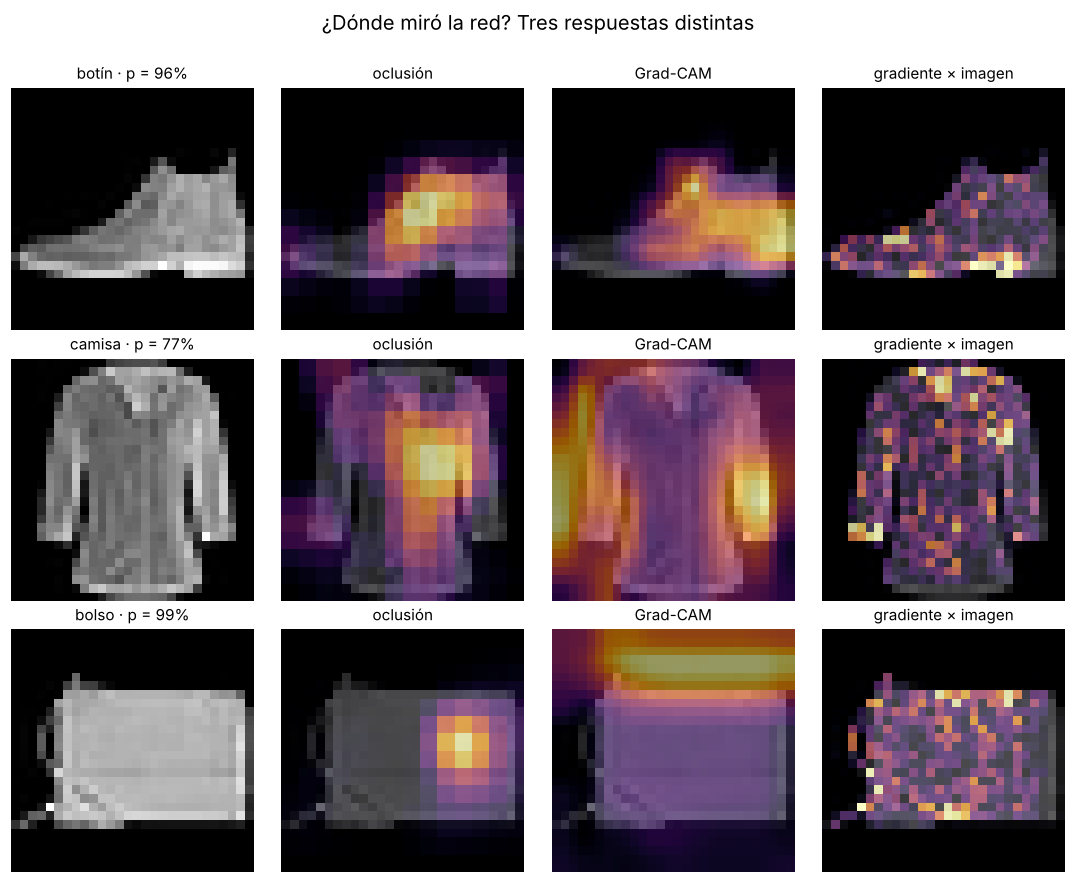

In [6]:
fotos = [int(np.where(y_test == c)[0][0]) for c in (9, 6, 8)]   # the first test botín, camisa and bolso


def escala(mapa):
    # Scale a map to 0..1 for drawing, using the 99th percentile so that one very bright pixel does not hide the rest
    return np.clip(mapa / (np.percentile(mapa, 99) + 1e-8), 0, 1)


fig, axs = plt.subplots(3, 4, figsize=(10, 8))
for fila, k in enumerate(fotos):
    x, c = x_test[k], int(y_test[k])
    p = cnn10.predict(x[None], verbose=0)[0, c]
    oc = np.clip(oclusion(cnn10, x, c), 0, None); oc = oc / (oc.max() + 1e-8)   # only the drops, scaled 0..1
    ver(x, axs[fila, 0], f"{CLASES[c]} · p = {p:.0%}")
    encima(x, oc, axs[fila, 1], "oclusión")
    encima(x, gradcam(cnn10, x, c), axs[fila, 2], "Grad-CAM")
    encima(x, escala(grad_x(cnn10, x, c)), axs[fila, 3], "gradiente × imagen")
    print(f"foto {k:2d} · {CLASES[c]:7s} · la red le da {p:.1%} a la clase correcta")
plt.suptitle("¿Dónde miró la red? Tres respuestas distintas", y=1.0); plt.tight_layout(); plt.show()

**Qué deberías ver:** el botín con ≈ **96 %**, la camisa con ≈ **77 %** y el bolso con ≈ **99 %**. Los tres métodos **no dicen lo mismo**:
- la **oclusión** ilumina zonas **dentro** de la prenda: la caña del botín, el centro de la camisa, el lado derecho del bolso;
- **Grad-CAM** ilumina zonas más grandes y, a veces, **fuera** de la prenda: el fondo vacío arriba del bolso, los costados de la camisa. Para la red, el **borde** de la silueta y que **no haya nada** en un lugar también son pistas;
- el **gradiente × imagen** se ve **más nítido**, píxel por píxel, y siempre **pegado a la silueta**: como multiplica por el brillo, fuera de la prenda vale 0.

**Léelo así:** el más bonito no es necesariamente el más fiel. Tres métodos, tres interpretaciones: **una explicación es una interpretación del modelo, no el modelo**. ¿Cuál le cree a la red? Para eso es la Parte 3.

### 💭 Para pensar

**1.** La oclusión necesitó 144 predicciones para una foto. ¿Qué problema tendría con una foto de 1 000 × 1 000 píxeles?

<details><summary>Ver respuesta</summary>

Con el mismo cuadro y el mismo paso serían **cientos de miles** de predicciones por foto: muy lento. Grad-CAM y el gradiente necesitan **una sola** pasada hacia adelante y una hacia atrás. Por eso se usan tanto.
</details>

**2.** ¿Por qué Grad-CAM se ve «borroso», en bloques?

<details><summary>Ver respuesta</summary>

Porque se calcula en la última capa convolucional, de **11 × 11**, y después se agranda a 28 × 28. Cada cuadrito del mapa resume una zona de la foto: dice *dónde*, pero no *qué píxel*.
</details>

---
## 3 · La prueba de cordura: ¿la explicación explica a la red?
📽 Lámina 31

**Qué vas a hacer:** repetir los mapas con una red **que no aprendió nada** (la misma forma, con pesos al azar) y medir cuánto se parecen a los de la red entrenada.

**La necesidad:** un mapa de calor puede **verse** convincente y no tener nada que ver con lo que la red aprendió.

**Ejemplo:** un traductor que, aunque cambies el discurso del orador, sigue diciendo frases parecidas porque se guía por el **tono de voz** y no por las palabras. Suena convincente, pero no traduce (lectura de tendencia).

**El nombre:** la **prueba de cordura** (Adebayo et al., 2018, Google Brain): borra lo que la red aprendió (pesos al azar) y vuelve a explicar. Si el método es fiel a la red, el mapa **debe cambiar por completo**, porque la red ya no sabe nada. Si casi no cambia, el método está mostrando **la foto**, no **la red**.

**La medida:** la **correlación de Spearman** entre los dos mapas (784 números cada uno): ordena los píxeles de más a menos importante en cada mapa y compara los dos órdenes.

$$\rho = 1 \text{ (mismo orden)} \qquad \rho = 0 \text{ (nada que ver)} \qquad \rho = -1 \text{ (orden al revés)}$$

**Léelo así:** para **pasar** la prueba, queremos un $\rho$ **cercano a 0**: la explicación cambió cuando cambió la red.

**Qué hace este código:**
- `rnd`: la misma arquitectura con otra semilla y **sin entrenar** (pesos al azar).
- Dibuja los mapas del botín con la red entrenada y con la red al azar.
- Calcula $\rho$ en las 30 primeras fotos de prueba, para los tres métodos, y dibuja el promedio. Tarda unos segundos.

🔮 **Antes de ejecutar:** ¿qué método crees que **no** pasará la prueba?

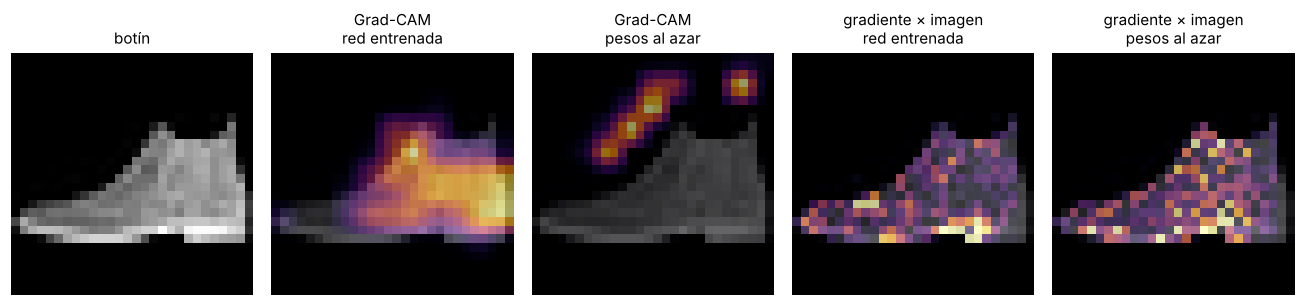

30 fotos · 7 s
Grad-CAM             ρ promedio = -0.12 → pasa (el mapa cambió)
oclusión             ρ promedio = -0.05 → pasa (el mapa cambió)
gradiente × imagen   ρ promedio = +0.90 → NO pasa (casi el mismo mapa)


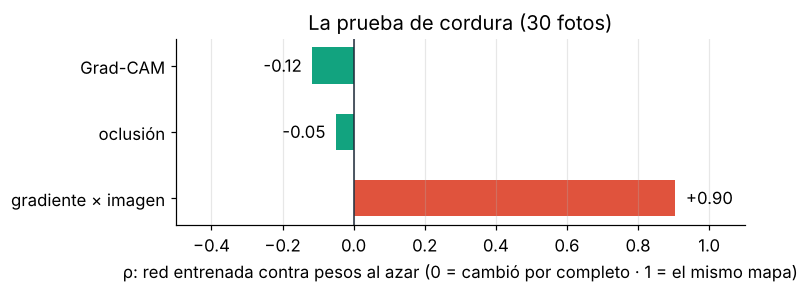

In [7]:
keras.utils.set_random_seed(SEED + 1)
rnd = keras.Sequential([keras.Input((28, 28, 1)), *base_conv(), layers.Dense(10, activation="softmax")])   # untrained twin

x = x_test[fotos[0]]                                       # the botín
mapas = {"Grad-CAM": (gradcam(cnn10, x, 9), gradcam(rnd, x, 9)),                              # already scaled 0..1
         "gradiente × imagen": (escala(grad_x(cnn10, x, 9)), escala(grad_x(rnd, x, 9)))}
fig, axs = plt.subplots(1, 5, figsize=(12, 2.8))
ver(x, axs[0], "botín")
for n, (nombre, (a, b)) in enumerate(mapas.items()):
    encima(x, a, axs[1 + 2 * n], f"{nombre}\nred entrenada")
    encima(x, b, axs[2 + 2 * n], f"{nombre}\npesos al azar")
plt.tight_layout(); plt.show()

corr = {"Grad-CAM": [], "oclusión": [], "gradiente × imagen": []}
metodo = {"Grad-CAM": gradcam, "oclusión": oclusion, "gradiente × imagen": grad_x}
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                        # a flat map (all zeros) gives NaN: we count it as 0
    for k in range(30):
        x, c = x_test[k], int(y_test[k])
        for nombre in ("Grad-CAM", "gradiente × imagen", "oclusión"):
            a = metodo[nombre](cnn10, x, c).ravel()        # map of the trained network
            b = metodo[nombre](rnd, x, c).ravel()          # map of the network that learned nothing
            r = spearmanr(a, b)[0]                         # rank correlation between the two maps
            corr[nombre].append(0.0 if np.isnan(r) else float(r))
rho = {nombre: float(np.mean(v)) for nombre, v in corr.items()}
print(f"30 fotos · {time.time() - t0:.0f} s")
for nombre, v in rho.items():
    print(f"{nombre:20s} ρ promedio = {v:+.2f} → {'pasa (el mapa cambió)' if abs(v) < 0.5 else 'NO pasa (casi el mismo mapa)'}")

fig, ax = plt.subplots(figsize=(7, 2.8))
nombres = list(rho)
ax.barh(nombres, [rho[n] for n in nombres], color=[MENTA if abs(rho[n]) < 0.5 else CORAL for n in nombres], height=0.55)
for i, n in enumerate(nombres): ax.text(rho[n] + (0.03 if rho[n] >= 0 else -0.03), i, f"{rho[n]:+.2f}", va="center", ha="left" if rho[n] >= 0 else "right")
ax.axvline(0, color=TINTA, lw=1); ax.set_xlim(-0.5, 1.1); ax.invert_yaxis(); ax.grid(axis="y", alpha=0)
ax.set_xlabel("ρ: red entrenada contra pesos al azar (0 = cambió por completo · 1 = el mismo mapa)")
ax.set_title("La prueba de cordura (30 fotos)"); plt.tight_layout(); plt.show()

**Qué deberías ver:** con pesos al azar, el mapa de **Grad-CAM cambia por completo** (ilumina manchas que no tienen nada que ver con el botín), pero el de **gradiente × imagen** sigue **pegado a la silueta** del botín, casi como con la red entrenada. En las 30 fotos:

| Método | ρ promedio | ¿Pasa? |
|---|---|---|
| Grad-CAM | ≈ **−0.12** | ✅ pasa: el mapa cambió |
| oclusión | ≈ **−0.05** | ✅ pasa |
| gradiente × imagen | ≈ **0.90** | ❌ **no pasa**: casi el mismo mapa aunque la red no sepa nada |

**Léelo así:** el gradiente × imagen se veía **más nítido**, pero buena parte de lo que muestra es **la foto misma** (multiplica por el brillo de cada píxel): ilumina la prenda sea cual sea la red. Es el traductor que sigue el tono de voz. Coincide con lo que encontraron Adebayo et al. (2018). **Una explicación también tiene que pasar pruebas antes de presentarse como verdad.**

### 💭 Para pensar

**1.** Si un método da casi el mismo mapa con la red entrenada y con una red al azar, ¿qué está explicando en realidad?

<details><summary>Ver respuesta</summary>

La **foto** (sus bordes, su brillo), no la **red**. Un mapa así puede convencer a cualquiera y, sin embargo, no dice nada de lo que la red aprendió.
</details>

**2.** ¿Pasar la prueba de cordura significa que Grad-CAM es «la verdad»?

<details><summary>Ver respuesta</summary>

**No.** Significa que pasó **una** prueba: depende de la red. Sigue siendo una interpretación (por ejemplo, a 11 × 11 no distingue píxeles). Pasar la prueba es necesario, no suficiente.
</details>

---
## 4 · Explicar una decisión de crédito
📽 Lámina 32

**Qué vas a hacer:** inventar una **cooperativa ficticia** con 6 000 socios, entrenar una red que predice quién cae en mora y explicar su decisión de dos maneras: **en general** (qué columnas importan) y **para una socia** (por qué la rechazó a ella).

**La necesidad:** la lectura empieza así: una socia recibe un «no» y pregunta, con todo derecho, **¿por qué?** Con la norma ecuatoriana de 2026, «así lo decidió el sistema» ya no basta.

**Los datos (todos inventados):** 7 columnas por socio:

| Columna | Qué es |
|---|---|
| `ingreso` | ingreso mensual, en dólares |
| `carga` | cuota del crédito ÷ ingreso (0.25 = la cuota es un cuarto del ingreso) |
| `antiguedad` | meses como socio |
| `atrasos` | pagos atrasados en los últimos 12 meses |
| `garante` | 1 si tiene garante, 0 si no |
| `ahorro` | ahorro en la cooperativa, en meses de ingreso |
| `rural` | 1 si vive en zona rural, 0 si urbana |

**Una ventaja de inventar el mundo:** nosotros **conocemos la regla** que decide la mora (está en el código: la carga solo pesa cuando pasa de 0.32; cada atraso suma, hasta dos; la antigüedad, el garante y el ahorro restan; vivir en zona rural suma un poco). En la vida real **nadie conoce esa regla**: por eso hay que explicar el modelo. Aquí podremos comprobar si la explicación tiene sentido.

**Qué hace este código:**
- Genera los 6 000 socios con un generador de números al azar con semilla (todos tenemos los mismos), con comentarios en cada columna.
- Separa 4 800 socios para entrenar y 1 200 para el examen, y normaliza cada columna (le resta su promedio y la divide por su desviación, como en la semana 1).
- Entrena una red densa 16 → 8 → 1 con salida **sigmoide**: la **probabilidad de mora**. La cooperativa **rechaza** si es 0.5 o más.
- Mide la **AUC**: si tomas al azar un socio que cayó en mora y uno que no, es la probabilidad de que la red le dé más riesgo al que cayó. 0.5 = azar; 1 = perfecto.

🔮 **Antes de ejecutar:** de cada 100 socios inventados, ¿cuántos crees que caen en mora?

In [8]:
rng = np.random.default_rng(SEED); n = 6000                          # seeded: everyone gets the same 6 000 members
rural = (rng.random(n) < 0.4).astype(int)                            # 40 % live in a rural zone
ingreso = np.round(rng.lognormal(np.log(620), 0.45, n) * np.where(rural, 0.85, 1.0), 2)   # around $620; rural earns 15 % less
carga = np.clip(rng.lognormal(np.log(0.25), 0.45, n), 0.05, 0.9)     # payment / income, around 0.25
antig = np.round(rng.exponential(40, n))                             # months as a member, 40 on average
atrasos = rng.poisson(0.35 + 0.25 * (carga > 0.4))                   # late payments in 12 months (more if the burden is high)
garante = (rng.random(n) < 0.42).astype(int)                         # 42 % have a guarantor
ahorro = np.round(rng.lognormal(np.log(0.8), 0.8, n), 2)             # savings, in months of income

# The hidden rule of this invented world (in real life nobody knows it)
logit = (-1.6 + 3.2 * np.tanh(4 * np.maximum(carga - 0.32, 0))      # the burden matters only above 0.32
         + 0.9 * np.minimum(atrasos, 2)                              # each late payment adds risk (up to two)
         - 1.4 * (1 - np.exp(-antig / 18))                           # seniority lowers it
         - 1.0 * garante - 0.5 * np.log1p(ahorro)                    # a guarantor and savings lower it
         + 0.5 * rural)                                              # living in a rural zone adds a little
mora = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)       # 1 = fell into default

cols = ["ingreso", "carga", "antiguedad", "atrasos", "garante", "ahorro", "rural"]
X = np.c_[ingreso, carga, antig, atrasos, garante, ahorro, rural].astype("float32")
Xtr, Xte, ytr, yte = X[:4800], X[4800:], mora[:4800], mora[4800:]  # 4 800 to train, 1 200 for the exam
mu, sd = Xtr.mean(0), Xtr.std(0)                                     # computed on the training members only
norm = lambda A: (A - mu) / sd
print(f"{n:,} socios · caen en mora: {mora.mean():.1%}")
display(pd.DataFrame(X[:5], columns=cols).assign(mora=mora[:5]))

keras.utils.set_random_seed(SEED)
m = keras.Sequential([keras.Input((7,)), layers.Dense(16, activation="relu"), layers.Dense(8, activation="relu"),
                      layers.Dense(1, activation="sigmoid")])        # output: probability of default
m.compile(optimizer=keras.optimizers.Adam(0.01), loss="binary_crossentropy", metrics=["accuracy"])
m.fit(norm(Xtr), ytr, epochs=30, batch_size=64, validation_split=0.2, verbose=0)

f = lambda A: m.predict(norm(A), verbose=0)[:, 0]                    # raw data -> probability of default
pte = f(Xte)
auc = roc_auc_score(yte, pte)
print(f"AUC: {auc:.2f} · exactitud: {((pte >= 0.5) == yte).mean():.1%} · rechaza (p ≥ 0.5) al {(pte >= 0.5).mean():.1%}")
print(f"(decir «nadie cae en mora» acertaría el {1 - yte.mean():.1%})")

6,000 socios · caen en mora: 12.5%


,ingreso,carga,antiguedad,atrasos,garante,ahorro,rural,mora
0,828.00,0.224,79.0,1.0,0.0,0.83,1.0,0
1,784.30,0.407,33.0,0.0,0.0,0.59,0.0,0
2,1081.72,0.274,7.0,0.0,0.0,0.58,0.0,0
3,342.86,0.333,20.0,1.0,0.0,1.42,1.0,0
4,176.72,0.137,50.0,1.0,0.0,1.24,1.0,1


AUC: 0.80 · exactitud: 89.2% · rechaza (p ≥ 0.5) al 5.7%
(decir «nadie cae en mora» acertaría el 88.2%)


**Qué deberías ver:** **12.5 %** de los socios cae en mora; una tabla con los 5 primeros socios; **AUC ≈ 0.80**, exactitud ≈ **89.2 %** y la red rechaza al ≈ **5.7 %**.

**Léelo así:** ojo con la exactitud: decir «nadie cae en mora» ya acierta el 88.2 %. Con clases desbalanceadas, la exactitud engaña (como vimos con la matriz de confusión en la semana 1); la AUC mide mejor si la red **ordena** bien el riesgo.

### Explicación general: importancia por permutación
**El nombre:** **importancia por permutación**. Para cada columna, la **mezclamos** al azar entre los socios del examen (rompemos su relación con la mora, sin cambiar sus valores) y medimos cuánto baja la AUC:

$$\text{importancia}_j = \text{AUC} - \text{AUC}(\text{con la columna } j \text{ mezclada})$$

**Léelo así:** "si al desordenar esta columna la red empeora mucho, la red **dependía** de ella". Si no cambia nada, la red no la usa.

**Qué hace este código:** mezcla cada una de las 7 columnas (una a la vez, siempre con la misma semilla) y dibuja cuánto baja la AUC.

🔮 **Antes de ejecutar:** ¿qué columna crees que es la más importante para la red?

carga       +0.125
atrasos     +0.051
garante     +0.049
antiguedad  +0.017
rural       +0.003
ingreso     +0.003
ahorro      -0.002


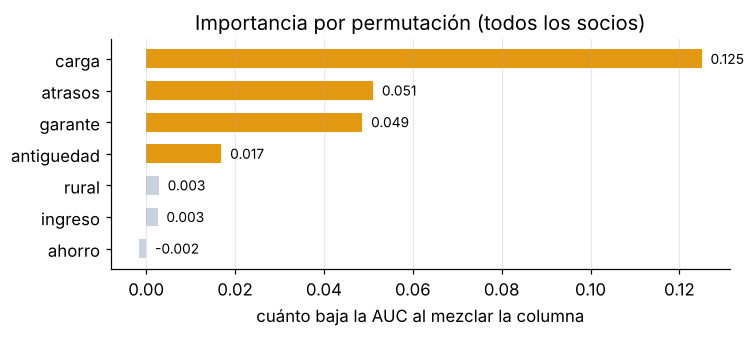

In [9]:
imp = {}
for j, c in enumerate(cols):
    Xp = Xte.copy()
    Xp[:, j] = np.random.default_rng(SEED).permutation(Xp[:, j])     # shuffle ONE column among the exam members
    imp[c] = auc - roc_auc_score(yte, f(Xp))                         # how much the AUC drops without it
orden = sorted(imp, key=imp.get)
for c in orden[::-1]: print(f"{c:11s} {imp[c]:+.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(orden, [imp[c] for c in orden], color=[AMBAR if imp[c] > 0.01 else "#C9D3DE" for c in orden], height=0.6)
for i, c in enumerate(orden): ax.text(max(imp[c], 0) + 0.002, i, f"{imp[c]:.3f}", va="center", fontsize=9)
ax.set_xlabel("cuánto baja la AUC al mezclar la columna"); ax.set_title("Importancia por permutación (todos los socios)")
ax.grid(axis="y", alpha=0); plt.tight_layout(); plt.show()

**Qué deberías ver:** **carga ≈ 0.125**, atrasos ≈ 0.051, garante ≈ 0.049, antigüedad ≈ 0.017; ingreso, rural y ahorro casi **0** (alrededor de 0.003, 0.003 y −0.002). Tiene sentido con la regla oculta: la carga, los atrasos y el garante son los que más pesan.

**Léelo así:** esto explica a la red **en general**, para todos los socios. Le sirve al **científico de datos** (¿usa lo que debería?). No le dice nada a una socia concreta.

### Explicación para una persona: SHAP
**Ejemplo:** repartir el mérito de un **gol** entre los jugadores que participaron en la jugada (lectura). Aquí, el «gol» es la probabilidad de mora de **una** socia, y los «jugadores» son sus 7 datos.

**El nombre:** **SHAP** (Lundberg y Lee, 2017). Parte del **promedio** (la probabilidad típica, «base») y reparte la diferencia entre las columnas:

$$p(\text{socia}) = \text{base} + \phi_{\text{ingreso}} + \phi_{\text{carga}} + \dots + \phi_{\text{rural}}$$

**Léelo así:** cada $\phi$ es **cuánto empujó** ese dato: positivo = hacia la mora (rechazar); negativo = hacia aprobar. Las $\phi$ suman exactamente la diferencia entre ella y el promedio. Para calcularlas, SHAP prueba qué pasa con la predicción cuando a la socia le «prestamos» los valores de otros socios en algunas columnas (aquí, 100 socios de referencia).

**Qué hace este código (primera celda):** importa SHAP; si no está instalado, lo instala (en Colab tarda unos segundos).

In [10]:
try:
    import shap                                     # usually already installed in Colab
except ImportError:
    %pip install -q shap
    import shap
print("SHAP", shap.__version__)

SHAP 0.54.1


**Qué hace este código (segunda celda):**
- Busca a **la socia**: la primera del examen con probabilidad de mora entre 0.6 y 0.8 (la red la rechaza).
- `shap.KernelExplainer(f, Xtr[:100])`: el explicador, con 100 socios de entrenamiento como referencia; `shap_values(...)` calcula sus 7 $\phi$.
- Dibuja la «cascada»: empieza en la base y suma cada $\phi$ hasta llegar a su probabilidad. Coral = empuja hacia rechazar; azul = hacia aprobar.

🔮 **Antes de ejecutar:** en general, la columna más importante fue la **carga**. ¿Será también la que más pesó **en su caso**?

La socia (examen n.º 25): ingreso $506 · carga 0.29 (cuota ≈ $144) · antigüedad 1 mes · 2 atrasos · garante: no · ahorro 1.5 meses · zona rural
Probabilidad de mora: 61% → RECHAZADA



base (promedio): 0.13
  atrasos     +0.30
  rural       +0.08
  garante     +0.04
  antiguedad  +0.04
  ingreso     +0.02
  carga       -0.02
  ahorro      +0.02
base + suma de las φ = 0.61  (su probabilidad: 0.61)


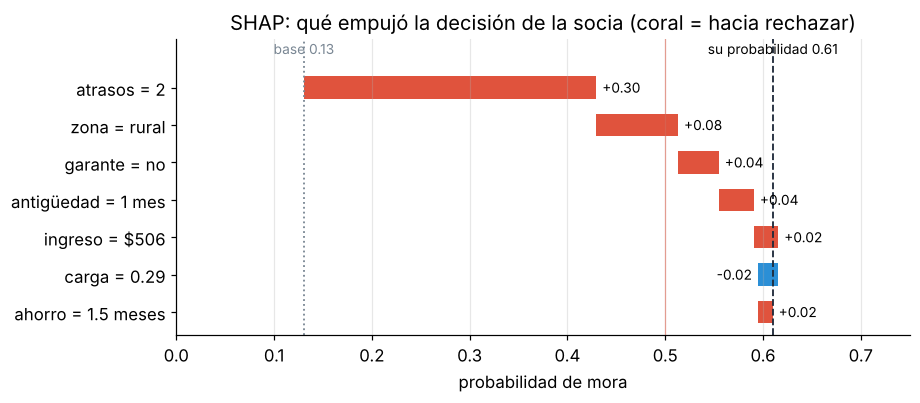

In [11]:
k = int(np.where((pte > 0.6) & (pte < 0.8))[0][0])  # the first exam member with p between 0.6 and 0.8
socia = Xte[k]
cuota = socia[1] * socia[0]
print(f"La socia (examen n.º {k}): ingreso ${socia[0]:,.0f} · carga {socia[1]:.2f} (cuota ≈ ${cuota:,.0f}) · "
      f"antigüedad {socia[2]:.0f} mes · {socia[3]:.0f} atrasos · garante: {'sí' if socia[4] else 'no'} · "
      f"ahorro {socia[5]:.1f} meses · zona {'rural' if socia[6] else 'urbana'}")
print(f"Probabilidad de mora: {pte[k]:.0%} → {'RECHAZADA' if pte[k] >= 0.5 else 'aprobada'}")

expl = shap.KernelExplainer(f, Xtr[:100])                          # 100 reference members
sv = expl.shap_values(socia[None], nsamples=500, silent=True)[0]   # her 7 contributions (phi)
base_shap = float(np.asarray(expl.expected_value).ravel()[0])      # the average probability ("base")
print(f"\nbase (promedio): {base_shap:.2f}")
for j in np.argsort(-np.abs(sv)): print(f"  {cols[j]:11s} {sv[j]:+.2f}")
print(f"base + suma de las φ = {base_shap + sv.sum():.2f}  (su probabilidad: {pte[k]:.2f})")

texto = {"ingreso": f"ingreso = ${socia[0]:,.0f}", "carga": f"carga = {socia[1]:.2f}", "antiguedad": f"antigüedad = {socia[2]:.0f} mes",
         "atrasos": f"atrasos = {socia[3]:.0f}", "garante": "garante = no" if socia[4] == 0 else "garante = sí",
         "ahorro": f"ahorro = {socia[5]:.1f} meses", "rural": "zona = rural" if socia[6] else "zona = urbana"}
orden = np.argsort(-np.abs(sv))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
acum = base_shap
for fila, j in enumerate(orden):
    ax.barh(fila, sv[j], left=acum, color=CORAL if sv[j] > 0 else AZUL, height=0.6)
    ax.text(acum + sv[j] + (0.006 if sv[j] > 0 else -0.006), fila, f"{sv[j]:+.2f}", va="center",
            ha="left" if sv[j] > 0 else "right", fontsize=9)
    acum += sv[j]
ax.axvline(base_shap, color="#7A8794", ls=":", lw=1.2); ax.text(base_shap, -0.9, f"base {base_shap:.2f}", ha="center", fontsize=9, color="#7A8794")
ax.axvline(acum, color=TINTA, ls="--", lw=1.2); ax.text(acum, -0.9, f"su probabilidad {acum:.2f}", ha="center", fontsize=9)
ax.axvline(0.5, color=CORAL, lw=0.8, alpha=0.5)
ax.set_yticks(range(len(orden))); ax.set_yticklabels([texto[cols[j]] for j in orden]); ax.invert_yaxis()
ax.set_xlim(0, 0.75); ax.set_ylim(len(orden) - 0.4, -1.3); ax.grid(axis="y", alpha=0)
ax.set_xlabel("probabilidad de mora"); ax.set_title("SHAP: qué empujó la decisión de la socia (coral = hacia rechazar)")
plt.tight_layout(); plt.show()

**Qué deberías ver:** la socia gana **$506**, su carga es **0.29** (cuota ≈ $144), tiene **1 mes** de antigüedad, **2 atrasos**, no tiene garante, ahorro de 1.5 meses y vive en zona **rural**. Probabilidad de mora: **61 %** → rechazada.

SHAP (base ≈ **0.13**): **atrasos +0.30** · rural +0.08 · sin garante +0.04 · antigüedad +0.04 · ingreso +0.02 · ahorro +0.02 · carga **−0.02**. Suman 0.61.

**Léelo así:** **lo que más importa en general (la carga) no es lo que más pesó en su caso (los atrasos).** Su carga (0.29) está por debajo del límite de la regla oculta (0.32): por eso casi no la perjudica. Y aparece algo incómodo: **vivir en zona rural** la empujó +0.08 hacia el rechazo. Lo veremos en la Parte 6.

### 💭 Para pensar

**1.** ¿Qué explicación le sirve al científico de datos y cuál a la socia?

<details><summary>Ver respuesta</summary>

La **importancia por permutación** le sirve al científico de datos: dice de qué depende la red **en general**. **SHAP** explica **su** caso: qué datos de ella empujaron hacia el rechazo. Pero ni siquiera SHAP le dice a la socia **qué hacer**: para eso es la Parte 5.
</details>

**2.** SHAP también es una interpretación. ¿Cómo sabemos aquí que no está inventando?

<details><summary>Ver respuesta</summary>

Porque inventamos el mundo y **conocemos la regla**: los atrasos sí suben el riesgo (hasta dos) y una carga de 0.29 está bajo el límite de 0.32. SHAP coincide. En la vida real no hay regla oculta para comparar: hay que usar pruebas como la de cordura y revisar con expertos del negocio.
</details>

---
## 5 · Lo que le sirve a la socia: el contrafactual
📽 Lámina 33

**Qué vas a hacer:** buscar el **cambio más pequeño** que convertiría el «no» en un «sí».

**La necesidad:** a la socia no le interesa la contribución de cada variable: le interesa **qué tendría que cambiar para que la aprueben** (lectura).

**El nombre:** una explicación **contrafactual**: «si X hubiera sido distinto, la decisión habría sido otra».

**Ejemplo:** «si su cuota fuera de $124 en vez de $144, la aprobaríamos». Se entiende sin saber nada de redes.

**Qué hace este código:**
- **Sin atrasos:** copia a la socia, pone sus atrasos en 0 y pregunta otra vez a la red.
- **Bajar la carga:** baja su carga de 0.01 en 0.01 (todo lo demás igual) hasta que la probabilidad quede bajo 0.5. Bajar la carga es, por ejemplo, **alargar el plazo** del crédito.
- Dibuja cómo cambia su probabilidad de mora según su carga.

🔮 **Antes de ejecutar:** ¿cuánto crees que tendría que bajar su cuota mensual para que la aprueben?

Sin los 2 atrasos: 12% (antes 61%)


Con carga 0.245: 48% → aprobada. Cuota ≈ $124 en vez de $144 (≈ $20 menos al mes)


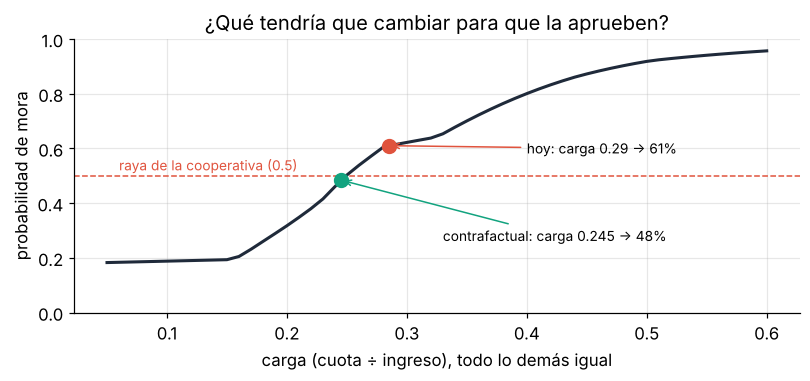

In [12]:
s3 = socia.copy(); s3[3] = 0                                # the same member, without the 2 late payments
print(f"Sin los 2 atrasos: {f(s3[None])[0]:.0%} (antes {pte[k]:.0%})")

cf = None
for c in np.arange(socia[1], 0.04, -0.01):                 # lower the burden 0.01 at a time
    s2 = socia.copy(); s2[1] = c                            # everything else stays the same
    if f(s2[None])[0] < 0.5:                                # the first burden that gets her approved
        cf = (c, f(s2[None])[0]); break
c_ok, p_ok = cf
print(f"Con carga {c_ok:.3f}: {p_ok:.0%} → aprobada. Cuota ≈ ${c_ok * socia[0]:,.0f} en vez de ${cuota:,.0f} "
      f"(≈ ${cuota - c_ok * socia[0]:,.0f} menos al mes)")

cargas = np.linspace(0.05, 0.6, 56)
variantes = np.repeat(socia[None], len(cargas), axis=0); variantes[:, 1] = cargas   # her, with 56 different burdens
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(cargas, f(variantes), color=TINTA, lw=2)
ax.axhline(0.5, color=CORAL, ls="--", lw=1); ax.text(0.06, 0.52, "raya de la cooperativa (0.5)", color=CORAL, fontsize=9)
ax.plot(socia[1], pte[k], "o", color=CORAL, ms=9)
ax.annotate(f"hoy: carga {socia[1]:.2f} → {pte[k]:.0%}", (socia[1], pte[k]), (0.40, 0.60), fontsize=9, va="center", arrowprops=dict(arrowstyle="->", color=CORAL))
ax.plot(c_ok, p_ok, "o", color=MENTA, ms=9)
ax.annotate(f"contrafactual: carga {c_ok:.3f} → {p_ok:.0%}", (c_ok, p_ok), (0.33, 0.28), fontsize=9, va="center", arrowprops=dict(arrowstyle="->", color=MENTA))
ax.set_xlabel("carga (cuota ÷ ingreso), todo lo demás igual"); ax.set_ylabel("probabilidad de mora"); ax.set_ylim(0, 1)
ax.set_title("¿Qué tendría que cambiar para que la aprueben?"); plt.tight_layout(); plt.show()

**Qué deberías ver:** **sin los 2 atrasos, su probabilidad baja a ≈ 12 %**. Bajando la carga, la primera que la aprueba es ≈ **0.245** (alrededor de **48 %**): una cuota de ≈ **$124** en vez de $144, unos **$20 menos al mes**, por ejemplo con un plazo más largo. En la curva, el riesgo sube rápido cuando la carga pasa de ≈ 0.3.

**Léelo así:** las dos explicaciones son verdaderas, pero **no sirven igual**:
- «sin atrasos» explica bien, pero **no se puede cambiar**: el pasado ya pasó (sí le dice qué cuidar de aquí en adelante);
- «con una cuota de unos $20 menos» es **accionable**: la socia y la cooperativa pueden hacer algo hoy.

Y hay contrafactuales que **no deberían ofrecerse nunca**: «si viviera en la ciudad…». Eso no es algo que una persona deba cambiar para recibir un crédito.

### 💭 Para pensar

**1.** ¿Qué le dirías a la socia, en dos frases y sin palabras técnicas?

<details><summary>Ver respuesta</summary>

Por ejemplo: «Su solicitud fue rechazada principalmente por los dos pagos atrasados del último año. Si alargamos el plazo para que su cuota baje a unos $124 al mes, la solicitud sería aprobada; y mantener sus pagos al día le ayudará en el futuro.» Además, por la norma ecuatoriana, debería poder pedir que **una persona** revise la decisión.
</details>

**2.** ¿Por qué el contrafactual cambia **una sola** cosa a la vez?

<details><summary>Ver respuesta</summary>

Para que sea **claro y accionable**: si cambias todo a la vez, la persona no sabe qué hacer. Es la misma idea del experimento controlado de la semana 1 (cambiar un valor a la vez).
</details>

---
## 6 · ¿Trata a todos por igual?
📽 Lámina 34

**Qué vas a hacer:** comparar lo que hace la red con los socios **rurales** y **urbanos** del examen, y después entrenar la misma red **sin la columna rural**.

**La necesidad:** SHAP mostró que vivir en zona rural empujó a la socia hacia el rechazo. ¿Pasa con todos? Una red puede ser muy exacta en promedio y tratar distinto a un grupo.

**El nombre:** dos tasas por grupo:
- **rechazo**: de cada 100 socios del grupo, a cuántos rechaza la red;
- **falsa alarma**: de cada 100 socios del grupo que **pagaron bien**, a cuántos rechazó igual (el error que más duele: un «no» injusto).

**Qué hace este código:**
- `tasas(mask)` calcula, para un grupo: cuántos son, cuántos cayeron de verdad en mora, el rechazo y la falsa alarma.
- La compara entre rural y urbana con la red de la Parte 4.
- Entrena la **misma red sin la columna rural** (solo 6 columnas, misma semilla, mismas épocas) y vuelve a comparar.

🔮 **Antes de ejecutar:** si quitamos la columna rural, ¿desaparecerá la diferencia entre zonas?

CON la columna rural (AUC 0.80)


,socios,mora_real,rechazo,falsa_alarma
rural,451,15.5%,8.9%,3.4%
urbana,749,9.5%,3.7%,2.2%


SIN la columna rural (AUC 0.79)


,socios,mora_real,rechazo,falsa_alarma
rural,451,15.5%,6.4%,1.6%
urbana,749,9.5%,5.6%,3.4%


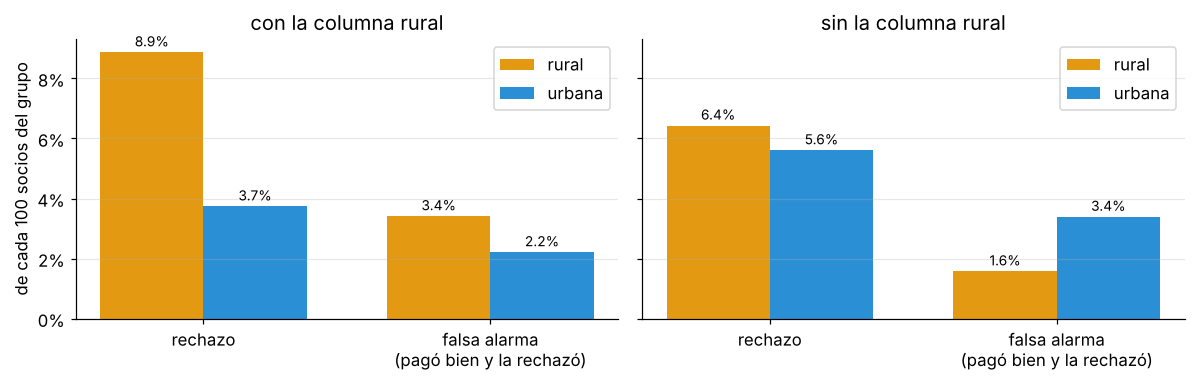

In [13]:
z = Xte[:, 6] == 1                                          # rural members of the exam


def tasas(mask, p):
    # For one group: size, real default rate, rejection rate and false-alarm rate (rejected although they paid)
    y, rechaza = yte[mask], p[mask] >= 0.5
    return dict(socios=int(mask.sum()), mora_real=y.mean(), rechazo=rechaza.mean(), falsa_alarma=rechaza[y == 0].mean())


con = pd.DataFrame({"rural": tasas(z, pte), "urbana": tasas(~z, pte)}).T

keras.utils.set_random_seed(SEED); keep = [0, 1, 2, 3, 4, 5]   # the same network WITHOUT the rural column
m2 = keras.Sequential([keras.Input((6,)), layers.Dense(16, activation="relu"), layers.Dense(8, activation="relu"),
                       layers.Dense(1, activation="sigmoid")])
m2.compile(optimizer=keras.optimizers.Adam(0.01), loss="binary_crossentropy", metrics=["accuracy"])
m2.fit(norm(Xtr)[:, keep], ytr, epochs=30, batch_size=64, validation_split=0.2, verbose=0)
pte_sin = m2.predict(norm(Xte)[:, keep], verbose=0)[:, 0]
sin = pd.DataFrame({"rural": tasas(z, pte_sin), "urbana": tasas(~z, pte_sin)}).T

def en_porcentaje(tabla_z):
    # Only for reading: the rates as percentages and the group size as an integer
    return tabla_z.assign(socios=tabla_z["socios"].astype(int),
                          **{c: tabla_z[c].map("{:.1%}".format) for c in ["mora_real", "rechazo", "falsa_alarma"]})


print(f"CON la columna rural (AUC {auc:.2f})"); display(en_porcentaje(con))
print(f"SIN la columna rural (AUC {roc_auc_score(yte, pte_sin):.2f})"); display(en_porcentaje(sin))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (titulo, tabla_z) in zip(axs, [("con la columna rural", con), ("sin la columna rural", sin)]):
    pos = np.arange(2)
    for d, (zona, color) in enumerate([("rural", AMBAR), ("urbana", AZUL)]):
        vals = [tabla_z.loc[zona, "rechazo"], tabla_z.loc[zona, "falsa_alarma"]]
        ax.bar(pos + (d - 0.5) * 0.36, vals, width=0.36, color=color, label=zona)
        for x0, v in zip(pos + (d - 0.5) * 0.36, vals): ax.text(x0, v + 0.002, f"{v:.1%}", ha="center", fontsize=9)
    ax.set_xticks(pos); ax.set_xticklabels(["rechazo", "falsa alarma\n(pagó bien y la rechazó)"]); ax.set_title(titulo)
    ax.grid(axis="x", alpha=0); ax.legend()
axs[0].set_ylabel("de cada 100 socios del grupo"); axs[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")   # 0.04 -> 4%
plt.tight_layout(); plt.show()

**Qué deberías ver:** en el examen hay 451 socios rurales y 749 urbanos. La **mora real** es distinta: rural ≈ **15.5 %**, urbana ≈ **9.5 %**.

| | Rechazo rural | Rechazo urbana | Falsa alarma rural | Falsa alarma urbana | AUC |
|---|---|---|---|---|---|
| **con** la columna rural | ≈ **8.9 %** | ≈ **3.7 %** | ≈ 3.4 % | ≈ 2.2 % | 0.80 |
| **sin** la columna rural | ≈ **6.4 %** | ≈ **5.6 %** | ≈ 1.6 % | ≈ 3.4 % | 0.79 |

**Léelo así:** con la columna, la red rechaza a los rurales **más del doble** y les da más falsas alarmas. Sin la columna, las tasas **se acercan** con un costo pequeño en AUC… pero ahora las falsas alarmas **urbanas** suben. Y la pregunta de fondo sigue ahí: **¿por qué la mora real es distinta?** (En este mundo inventado sabemos que los rurales ganan 15 % menos y que la regla les suma riesgo; en la vida real habría que averiguarlo.) Además, otras columnas, como el ingreso, pueden «delatar» la zona aunque la borres.

**No hay una respuesta solo técnica:** decidir qué es justo aquí es una decisión de la cooperativa, con las personas afectadas, no de la red.

### 💭 Para pensar

**1.** Si quitas la columna rural, ¿la red deja de «saber» quién es rural?

<details><summary>Ver respuesta</summary>

No del todo: columnas como el **ingreso** (más bajo en zona rural en estos datos) llevan parte de esa información. Borrar una columna no borra la relación. Por eso hay que **medir por grupo**, como hicimos, y no solo confiar en lo que se quitó.
</details>

**2.** ¿Qué preferirías: tasas de rechazo parecidas entre zonas o la mayor AUC posible? ¿Quién debería decidirlo?

<details><summary>Ver respuesta</summary>

No hay una respuesta única: depende de qué error se considera más grave y de qué es justo para la cooperativa y sus socios. Lo importante es que la decisión sea **explícita, documentada y revisable** por personas, no un efecto escondido del modelo.
</details>

---
## 🏁 Resumen en 5 líneas
1. **Transfer learning** reutiliza lo que una red ya aprendió: congelar la base y entrenar la cabeza (3 204 de 8 004 parámetros). Con 5 fotos por clase gana ≈ 15 puntos; con 100, casi nada.
2. **Oclusión, Grad-CAM y gradiente × imagen** responden «¿dónde miró?», y no dicen lo mismo: **son interpretaciones**, no el modelo.
3. **La prueba de cordura:** con pesos al azar, Grad-CAM (ρ ≈ −0.12) y la oclusión (≈ −0.05) cambian; el gradiente × imagen casi no (≈ 0.90): explicaba **la foto**, no la red.
4. Para el **científico de datos**, la importancia por permutación (la carga, en general); para **la socia**, SHAP (sus atrasos) y, sobre todo, el **contrafactual** accionable (una cuota de unos $20 menos).
5. **Medir por grupo:** la red rechazaba más del doble a los rurales; quitar la columna acerca las tasas, pero **no hay una respuesta solo técnica**.

### 📖 Lo que dice la lectura de tendencia (lámina 36)
- **Ecuador, marzo de 2026:** una norma de la Superintendencia de Protección de Datos Personales pide evaluar el impacto de sistemas riesgosos, **revisión humana** de decisiones automatizadas con efectos jurídicos y el **derecho a pedir una explicación** de la lógica del algoritmo. Las Partes 4 a 6 son lo que una cooperativa necesitaría para cumplirla de verdad: una explicación fiel, una que le sirva a la persona y una revisión por grupos.
- **Adebayo et al. (2018):** la prueba de cordura de la Parte 3. Una explicación también tiene que pasar pruebas antes de presentarse como verdad.
- **Rudin (2019):** en decisiones de alto impacto, propone usar **modelos interpretables por diseño** (por ejemplo, una tabla de puntos que se lee línea por línea) en lugar de explicar cajas negras después. ¿Cuánta exactitud estarías dispuesto a sacrificar por entender un modelo?

## ✍️ Ejercicios

Se responden **leyendo los resultados de este notebook y pensando**: no hay que programar nada. Escribe tu respuesta (dos a cinco líneas) en una celda de texto debajo de cada uno y después compárala con la respuesta plegada.

**Ejercicio 1.** **¿Transfer en tu proyecto?** Con la tabla de la Parte 1, di cuántos puntos ganó la red congelada frente a «desde cero» con 5 fotos por clase y con 100. Si tu proyecto tuviera 300 ejemplos etiquetados, ¿usarías transfer learning? ¿Qué le preguntarías a quien entrenó la red base antes de usarla?

<details><summary>Ver una respuesta posible</summary>

Con 5 fotos por clase, congelar ganó unos **15 puntos** (30.6 → 45.9 %; el ajuste fino, 47.2 %). Con 100, perdió unos 2 (68.8 → 66.7 %): con datos suficientes, la experiencia heredada ya no ayuda. Con 300 ejemplos en total (pocos para deep learning) **sí** probaría transfer learning, comparando con el simulacro contra «desde cero». Preguntaría **con qué datos** se entrenó la base (de qué lugar, de qué época, con qué personas), porque heredamos sus hábitos y posibles sesgos sin poder auditarlos del todo.
</details>

**Ejercicio 2.** **El mapa más bonito.** Un colega quiere poner en su informe el mapa de gradiente × imagen «porque se ve más nítido y se ve la forma del botín». Con los resultados de las Partes 2 y 3, explícale por qué eso es justamente el problema.

<details><summary>Ver una respuesta posible</summary>

Se ve la forma del botín porque el método **multiplica por el brillo de la foto**: ilumina la prenda sea cual sea la red. En la prueba de cordura, su mapa con pesos al azar se parece al de la red entrenada (ρ ≈ 0.90): no está mostrando lo que la red aprendió. Grad-CAM (ρ ≈ −0.12) y la oclusión (≈ −0.05) sí cambian cuando la red cambia. En el informe debería ir uno de esos, y mencionar que pasó la prueba de cordura.
</details>

**Ejercicio 3.** **Dos explicaciones, dos destinatarios.** Con las salidas de las Partes 4 y 5, escribe (a) una explicación de la decisión para **la socia**, en lenguaje sencillo y en no más de tres frases, y (b) una para el **equipo de datos** de la cooperativa. ¿Qué número de este notebook **no** pondrías en la de la socia?

<details><summary>Ver una respuesta posible</summary>

(a) «Su solicitud fue rechazada principalmente por los dos pagos atrasados de los últimos 12 meses. Si ajustamos el plazo para que su cuota baje unos $20 (a unos $124 al mes), la solicitud sería aprobada. Puede pedir que una persona de la cooperativa revise esta decisión.» (b) «La red (AUC 0.80) depende sobre todo de la carga, los atrasos y el garante (importancia por permutación). En este caso, SHAP atribuye +0.30 a los atrasos y +0.08 a la zona rural; hay que revisar el efecto de la zona por grupo (Parte 6).» En la de la socia **no** pondría los valores SHAP ni la AUC (no le dicen qué hacer), y no le ofrecería contrafactuales que no puede o no debe cambiar, como la zona.
</details>

**Ejercicio 4.** **¿Problema resuelto?** El gerente propone: «quitamos la columna rural y listo, ya no discriminamos». Con la tabla de la Parte 6, explica qué mejoró, qué empeoró y qué pregunta queda abierta.

<details><summary>Ver una respuesta posible</summary>

Mejoró: el rechazo rural bajó de ≈ 8.9 % a ≈ 6.4 % y quedó cerca del urbano (≈ 5.6 %), y las falsas alarmas rurales bajaron (≈ 3.4 → 1.6 %), con un costo pequeño en AUC (0.80 → 0.79). Empeoró: las falsas alarmas **urbanas** subieron (≈ 2.2 → 3.4 %): ahora el «no» injusto se movió hacia otro grupo. Queda abierto **por qué** la mora real es distinta (15.5 % contra 9.5 %) y si otras columnas, como el ingreso, siguen delatando la zona. No es «listo»: es una decisión que hay que documentar, medir por grupo y revisar con personas.
</details>

---
## 🏁 Para comprobar que entendiste
Responde cada pregunta **antes** de abrir la respuesta. Si fallas alguna, vuelve a la parte indicada.

### 💭 Preguntas

**1.** En transfer learning, ¿qué es «congelar» y qué es el «ajuste fino»?

<details><summary>Ver respuesta</summary>

**Congelar** (`trainable = False`): copiar la base de una red ya entrenada y entrenar solo la cabeza nueva. **Ajuste fino**: después, desbloquear todo y seguir entrenando con un learning rate muy pequeño (0.0001) para acomodar la base sin borrar su experiencia. (Parte 1)
</details>

**2.** ¿Cuándo ayudó más el transfer learning en este notebook, y por qué?

<details><summary>Ver respuesta</summary>

Con **muy pocos datos** (5 fotos por clase: ≈ 46 % contra ≈ 31 %): la cabeza solo aprende 3 204 parámetros y recibe rasgos ya útiles. Con 100 fotos por clase, entrenar desde cero empató o ganó. (Parte 1)
</details>

**3.** ¿Qué mide la oclusión, en una frase?

<details><summary>Ver respuesta</summary>

Cuánto **baja la probabilidad** de la clase correcta cuando tapamos cada zona de la foto: si baja mucho, esa zona le importaba a la red. (Parte 2)
</details>

**4.** ¿De qué capa sale el mapa de Grad-CAM y por qué se ve en bloques?

<details><summary>Ver respuesta</summary>

De la **última capa convolucional** (11 × 11 × 32): pesa sus 32 mapas con el gradiente promedio, se queda con lo positivo y lo agranda a 28 × 28. Por eso marca zonas, no píxeles. (Parte 2)
</details>

**5.** ¿En qué consiste la prueba de cordura y qué resultado queremos?

<details><summary>Ver respuesta</summary>

Repetir la explicación con la **misma red con pesos al azar**. Queremos que el mapa **cambie** (ρ cercano a 0): si casi no cambia, la explicación no explicaba a la red. (Parte 3)
</details>

**6.** ¿Qué método no pasó la prueba de cordura y qué estaba mostrando en realidad?

<details><summary>Ver respuesta</summary>

El **gradiente × imagen** (ρ ≈ 0.90): mostraba sobre todo **la foto** (la silueta, porque multiplica por el brillo), no lo que la red aprendió. (Parte 3)
</details>

**7.** ¿Por qué la exactitud (89.2 %) no basta para evaluar la red de la cooperativa?

<details><summary>Ver respuesta</summary>

Porque solo el 11.8 % del examen cae en mora: decir «nadie cae» ya acierta el 88.2 %. La **AUC** (0.80) mide si la red ordena bien el riesgo. (Parte 4)
</details>

**8.** ¿Qué diferencia hay entre la importancia por permutación y SHAP?

<details><summary>Ver respuesta</summary>

La **importancia por permutación** es **global**: de qué columnas depende la red con todos los socios (la carga). **SHAP** es **local**: cuánto empujó cada dato en **un** caso (para la socia, los atrasos, +0.30). (Parte 4)
</details>

**9.** ¿Qué es un contrafactual y por qué le sirve más a la socia que SHAP?

<details><summary>Ver respuesta</summary>

Es el cambio más pequeño que cambiaría la decisión («con una cuota de unos $20 menos, la aprobaríamos»). Le dice **qué puede hacer**, que es lo que le importa; SHAP le dice qué pesó, que le importa al analista. (Parte 5)
</details>

**10.** Al quitar la columna rural, ¿qué pasó con las tasas por zona? ¿Se resolvió el problema?

<details><summary>Ver respuesta</summary>

El rechazo se acercó (≈ 6.4 % rural contra ≈ 5.6 % urbana) con un costo pequeño en AUC, pero subieron las falsas alarmas urbanas y sigue abierta la pregunta de por qué la mora real es distinta. **No hay una respuesta solo técnica.** (Parte 6)
</details>

---
### 🧪 Experimento 6 (opcional): ¿dónde pones la raya?
📽 Lámina 37

**La pregunta:** la cooperativa rechaza cuando la probabilidad de mora es **0.5 o más**. Esa raya (el **umbral**) no la decide la red: la decide **una persona**. ¿Qué cambia si la mueves?

**Qué hace este código:**
- `umbral = 0.5` decide desde qué probabilidad se rechaza. **No entrena nada**: usa las probabilidades de la red de la Parte 4.
- Muestra a cuántos socios rechaza, cuántos de los que **sí** cayeron en mora detecta, las falsas alarmas, y el rechazo por zona.

🔮 **Antes de ejecutar (con `umbral = 0.3`):** ¿rechazará a más o a menos socios? ¿Qué pasa con las falsas alarmas?

In [14]:
umbral = 0.5                                     # reject if p >= umbral   (🧪 try 0.3, then 0.7)

rechaza = pte >= umbral
print(f"umbral {umbral} · rechaza al {rechaza.mean():.1%} de los socios ({rechaza.sum()} de {len(pte):,})")
print(f"  de los {int(yte.sum())} que SÍ cayeron en mora, detecta al {rechaza[yte == 1].mean():.1%}")
print(f"  falsas alarmas (pagaron bien y los rechazó): {rechaza[yte == 0].mean():.1%}")
print(f"  rechazo por zona · rural {rechaza[z].mean():.1%} · urbana {rechaza[~z].mean():.1%}")

umbral 0.5 · rechaza al 5.7% de los socios (68 de 1,200)
  de los 141 que SÍ cayeron en mora, detecta al 28.4%
  falsas alarmas (pagaron bien y los rechazó): 2.6%
  rechazo por zona · rural 8.9% · urbana 3.7%


**Qué deberías ver:** con `umbral = 0.5`: rechaza al ≈ **5.7 %** (68 de 1 200), detecta al ≈ **28 %** de los 141 que cayeron en mora, falsas alarmas ≈ **2.6 %**, rechazo rural ≈ 8.9 % y urbano ≈ 3.7 %.

Con `0.3`: rechaza al ≈ **10.2 %**, detecta al ≈ **40 %** de la mora, pero las falsas alarmas suben a ≈ **6.2 %** (rural 13.5 % · urbana 8.3 %). Con `0.7`: rechaza solo al ≈ **3.1 %**, detecta al ≈ **18 %** y las falsas alarmas bajan a ≈ **1.0 %** (rural 4.9 % · urbana 2.0 %).

🧪 **Experimenta:** cambia `umbral = 0.5` por `0.3` y ejecuta otra vez; después prueba `0.7`. ¿Qué umbral elegirías tú, y a quién le preguntarías antes?

### 💭 Para pensar

**1.** ¿Por qué no existe un umbral «correcto» calculado por la red?

<details><summary>Ver respuesta</summary>

Porque cada umbral reparte los errores de otra forma: más bajo, detecta más mora pero niega crédito a más personas que habrían pagado; más alto, al revés. Cuál error pesa más es una decisión **del negocio y de ética**, no de la red.
</details>

**2.** Con la norma ecuatoriana, ¿qué debería poder explicar la cooperativa sobre el umbral?

<details><summary>Ver respuesta</summary>

Que existe, **quién** lo eligió, **por qué** ese valor y cómo afecta a cada grupo. Explicar la lógica del algoritmo incluye las decisiones humanas que lo rodean, no solo los pesos de la red.
</details>

---
**¿Te quedó alguna duda?** Repasa las slides interactivas y la guía de estudio desde la página del curso (Semana 3). Para cerrar la semana, vuelve a la pregunta del entregable de la semana 1: **¿le creerías a tu red?** Ahora tienes más formas de responderla: ¿generaliza?, ¿aguanta cambios?, ¿de dónde viene lo que sabe?, ¿puede explicar lo que decide?, ¿la explicación pasa pruebas?, ¿trata a todos por igual?